# Reviewing random-forest feature selection

Read-only review of the completed four-recipe training study. The study identity
is pinned explicitly below. All tables/figures share their preparation with the
app and submission documents. The previous three-recipe notebook is preserved.

To compute a new study explicitly, run `python3 run_feature_selection.py` from
the project root; do not put that command in report-rendering cells.

In [1]:
from pathlib import Path
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
if ROOT.name == "0_3_Feature_Selection":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ["MLFACTOR_READ_ONLY"] = "1"
from research.store import ExperimentStore
from research.feature_studies import load_feature_study, feature_audit
from research.feature_reporting import (
    method_notes, importance_table, importance_figure, selection_overlap,
    prediction_summary, portfolio_table, portfolio_figure, forest_findings,
)
STUDY_ID = "features_20261109T202318_8b01fe74"
study = load_feature_study(ExperimentStore(ROOT / "artifacts"), STUDY_ID)
display(Markdown(method_notes()))
print("Saved study:", STUDY_ID)
display(pd.DataFrame([{"Recipe": key, "Saved run": value}
                     for key, value in study["metadata"]["runs"].items()]))

**All 20 factors** is the exploratory reference. Each learned recipe selects
at most ten inputs using only outcomes available at that historical training
date, then independently retrains each classifier. Preprocessing and selection
remain inside the model pipeline, including inside future tuning folds.

- **ANOVA top 10:** rank factors individually by training separation between
  loss and non-loss outcomes; retain the highest-ranked varying inputs.
- **Correlation-pruned up to 10:** follow the ANOVA ranking while rejecting
  factors too correlated with a higher-ranked retained input. Use the saved
  correlation threshold; do not backfill rejected duplicates.
- **Random forest top 10:** fit a separate selector forest on all candidate
  inputs and rank their mean decrease in impurity. Retain the highest-ranked
  varying inputs, then fit the chosen prediction model. A forest selector can
  supply inputs to logistic regression, naive Bayes, boosting or another forest.

**Reading the forest chart:** longer bars indicate more training split
importance. Highlighted bars are the selected inputs. Error bars show standard
deviation across trees, not confidence intervals or future-return uncertainty.
Importance does not give the direction of an effect or establish causality.
Correlated factors can share importance, and inputs with more possible split
points can receive inflated importance. ANOVA scores and forest importances have
different units; compare selected names and later outcomes across methods.

**Reading the comparisons:** lower Brier score and log loss are better. Compare
each selected recipe with the same predictor using all twenty factors and with
the historical event-frequency control. Then compare the resulting portfolios
over identical months. Feature selection changes ML inputs; non-ML rules remain
unchanged references. A favorable return does not establish useful prediction.
Annual masks may differ; their union is not a fixed final ten-factor model.

Method references: textbook chapter 29 introduces tree importance and random
forests; [sklearn's forest example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html)
illustrates importance and tree variability. See its
[permutation-importance guide](https://scikit-learn.org/stable/modules/permutation_importance.html)
for further interpretation limits. Permutation selection is not part of this study.


Saved study: features_20261109T202318_8b01fe74


,Recipe,Saved run
0,all_20,20261109T202421_184e95372ab2
1,anova_10,20261109T202516_039a5a86258b
2,pruned_10,20261109T202612_7da383c77e5b
3,forest_10,20261109T202931_597510736fb4


## What was selected?

Choose a saved historical origin using `SNAPSHOT`. The selector forest uses all
twenty candidates and the downstream classifier is retrained on the retained
ten. Tree variability describes this fit, not confidence about future returns.

,feature,group,meaning,rank,score,importance_std
0,Div_Yld,Valuation / payout,Dividend yield,1,0.103349,0.068836
1,Ocf_Ce,Cash flow,Operating cash flow / capital employed,2,0.087515,0.052694
2,Fcf_Yld,Valuation / payout,Free cash flow yield,3,0.086404,0.045150
3,Tev_Less_Mktcap,Debt,Total enterprise value minus market capitaliza...,4,0.081036,0.048784
4,Share_Turn_3M,Trading activity,Average share turnover over 3 months,5,0.072464,0.061928
5,Ev_Ebitda,Valuation / payout,Enterprise value / EBITDA,6,0.070386,0.046254
6,Share_Turn_6M,Trading activity,Average share turnover over 6 months,7,0.062124,0.060915
7,Capex_Sales,Investment,Capital expenditure / sales,8,0.060420,0.041817
8,Share_Turn_12M,Trading activity,Average share turnover over 12 months,9,0.056824,0.061115
9,Tot_Debt_Rev,Debt,Total debt / revenue,10,0.046166,0.039074


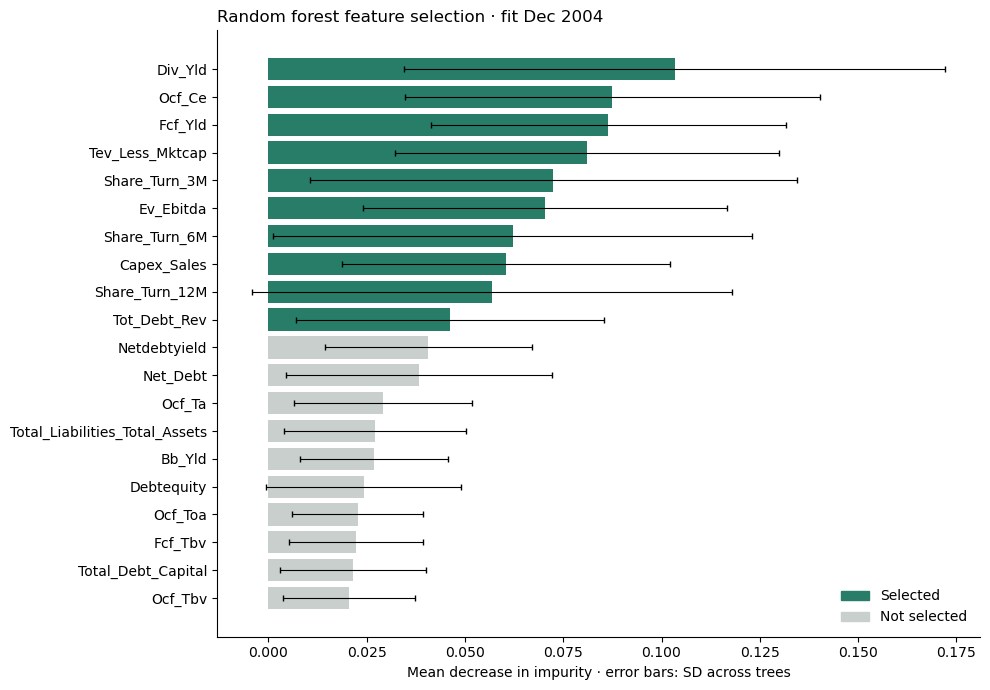

,ANOVA top 10,Correlation-pruned up to 10 (|r| < 0.90),Random forest top 10
ANOVA top 10,10,7,8
Correlation-pruned up to 10 (|r| < 0.90),7,10,6
Random forest top 10,8,6,10


In [2]:
MODEL = "logistic"
SNAPSHOT = study["fits"].fit_snapshot.min()
rows = importance_table(study, MODEL, snapshot=SNAPSHOT)
display(rows.loc[rows.selected, ["feature", "group", "meaning", "rank", "score", "importance_std"]])
figure = importance_figure(study, MODEL, snapshot=SNAPSHOT)
display(figure)
plt.close(figure)
display(selection_overlap(study, MODEL, SNAPSHOT))

## Does restriction improve predictions?

Lower Brier score/log loss is better. Compare both within-model changes and the
historical event-frequency control. These are training-validation observations,
not the official frozen final test.

In [3]:
display(Markdown(forest_findings(study)))
display(prediction_summary(study)[[
    "model_id", "recipe", "brier_score", "log_loss", "roc_auc",
    "Brier change vs all 20", "Log-loss change vs all 20",
]].round(6))

Forest selection lowers Brier score relative to all twenty factors for 2 of 4 predictors. 0 of the forest-selected predictors beat the historical event-frequency control on Brier score (control: 0.249023). These are training-validation comparisons; portfolio effects must be assessed separately. They do not declare a final feature/model choice or provide a tuned frozen-test result.

,model_id,recipe,brier_score,log_loss,roc_auc,Brier change vs all 20,Log-loss change vs all 20
0,logistic,all_20,0.249667,0.692578,0.500801,0.000000,0.000000
1,logistic,anova_10,0.249434,0.692080,0.502109,-0.000233,-0.000498
2,logistic,pruned_10,0.249507,0.692236,0.502248,-0.000160,-0.000342
3,logistic,forest_10,0.249474,0.692174,0.503437,-0.000192,-0.000404
4,naive_bayes,all_20,0.259759,0.714980,0.509354,0.000000,0.000000
5,naive_bayes,anova_10,0.257497,0.709745,0.508686,-0.002262,-0.005235
6,naive_bayes,pruned_10,0.254021,0.701998,0.506972,-0.005738,-0.012982
7,naive_bayes,forest_10,0.254489,0.702917,0.509923,-0.005270,-0.012064
8,random_forest,all_20,0.249387,0.692021,0.505785,0.000000,0.000000
9,random_forest,anova_10,0.249428,0.692101,0.508019,0.000041,0.000080


## Does it improve the portfolio?

The default example uses annual consistency, positive three-month momentum and
cash. Change `MODEL` and `STRATEGY` to inspect other recorded cases. The unchanged
non-ML strategy is the same reference across all recipes.

,recipe,cagr,annualized_log_growth,sharpe,sortino,max_drawdown,avg_one_way_turnover,avg_cash_weight,change_cagr_vs_all20
52,all_20,0.035099,0.034497,0.434859,0.704686,-0.175582,0.207378,0.563740,0.000000
108,anova_10,0.035230,0.034624,0.435831,0.706767,-0.175590,0.207478,0.563433,0.000131
164,pruned_10,0.035144,0.034541,0.435164,0.705400,-0.175636,0.207440,0.563566,0.000046
220,forest_10,0.035219,0.034613,0.435711,0.706545,-0.175615,0.207546,0.563278,0.000120


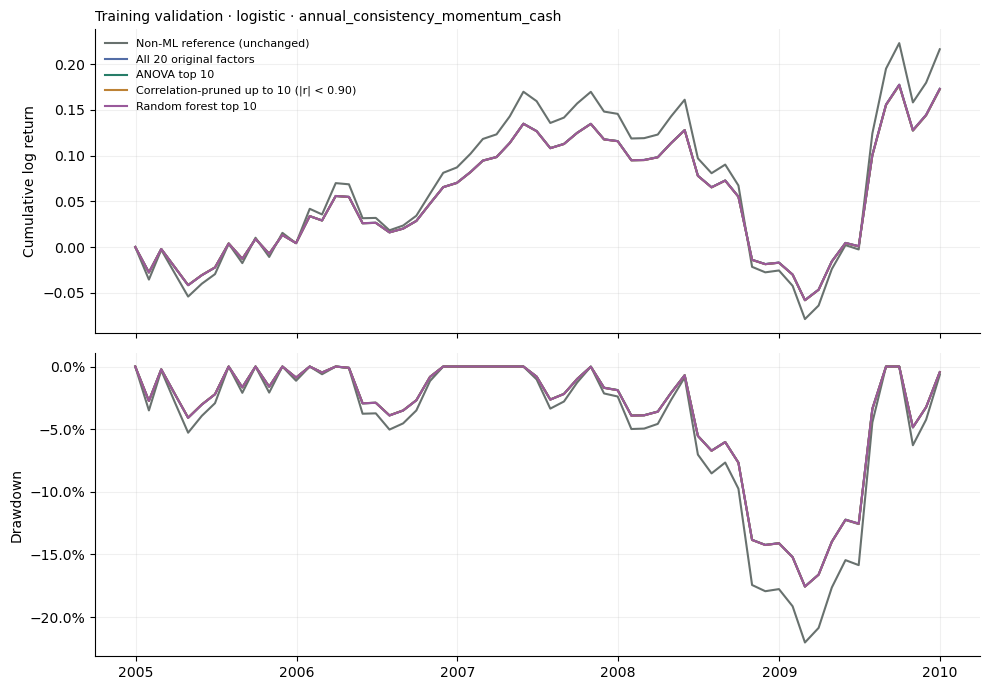

In [4]:
STRATEGY = "annual_consistency_momentum_cash"
display(portfolio_table(study, MODEL, [STRATEGY])[[
    "recipe", "cagr", "annualized_log_growth", "sharpe", "sortino", "max_drawdown",
    "avg_one_way_turnover", "avg_cash_weight", "change_cagr_vs_all20",
]].round(6))
figure = portfolio_figure(study, MODEL, STRATEGY, cumulative_log=True)
display(figure)
plt.close(figure)

## Audit timing and actual masks

At most ten features are used per selected model. Methods can change their
chosen names annually; the annual union is not one frozen final subset.
Inspect the full audit for exclusions, training cutoff and per-tree variation.
No hyperparameter search or final test evaluation is performed by this notebook.

In [5]:
fits = study["fits"]
assert fits.loc[fits.recipe.ne("all_20"), "n_features"].le(10).all()
assert fits.trained_through_return_month.le(fits.fit_snapshot).all()
assert fits.groupby(["recipe", "fit_snapshot"]).fitted_features.nunique().eq(1).all()
audit = feature_audit(fits)
display(audit.loc[audit.model_id.eq(MODEL) & audit.recipe.eq("forest_10")])

,feature,score,score_type,importance_std,ranking_informative,rank,selected,reason,correlated_with,absolute_correlation,model_id,fit_snapshot,recipe,training_rows,trained_through_return_month
800,Div_Yld,0.103349,mean_decrease_impurity,0.068836,True,1,True,selected,,0.0,logistic,2004-12-31,forest_10,69108,2004-12-31
801,Ocf_Ce,0.087515,mean_decrease_impurity,0.052694,True,2,True,selected,,0.0,logistic,2004-12-31,forest_10,69108,2004-12-31
802,Fcf_Yld,0.086404,mean_decrease_impurity,0.045150,True,3,True,selected,,0.0,logistic,2004-12-31,forest_10,69108,2004-12-31
803,Tev_Less_Mktcap,0.081036,mean_decrease_impurity,0.048784,True,4,True,selected,,0.0,logistic,2004-12-31,forest_10,69108,2004-12-31
804,Share_Turn_3M,0.072464,mean_decrease_impurity,0.061928,True,5,True,selected,,0.0,logistic,2004-12-31,forest_10,69108,2004-12-31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,Debtequity,0.030955,mean_decrease_impurity,0.022984,True,16,False,outside selected count,,0.0,logistic,2008-12-31,forest_10,126417,2008-12-31
896,Total_Debt_Capital,0.024124,mean_decrease_impurity,0.018105,True,17,False,outside selected count,,0.0,logistic,2008-12-31,forest_10,126417,2008-12-31
897,Fcf_Tbv,0.022073,mean_decrease_impurity,0.014146,True,18,False,outside selected count,,0.0,logistic,2008-12-31,forest_10,126417,2008-12-31
898,Bb_Yld,0.022021,mean_decrease_impurity,0.016954,True,19,False,outside selected count,,0.0,logistic,2008-12-31,forest_10,126417,2008-12-31
